In [ ]:
import pandas as pd

In [ ]:
from google.colab import files
import zipfile
uploaded = files.upload()

with zipfile.ZipFile('Metro_Interstate_Traffic_Volume.csv.zip', 'r') as zip_ref:
    zip_ref.extractall('Metro_Interstate_Traffic_Volume')

Saving Metro_Interstate_Traffic_Volume.csv.zip to Metro_Interstate_Traffic_Volume.csv (4).zip


In [ ]:
df = pd.read_csv('Metro_Interstate_Traffic_Volume.csv.zip')

In [ ]:
# Display the first few rows of the DataFrame
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,02-10-2012 09:00
1,4516,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,02-10-2012 10:00
2,4767,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 11:00
3,5026,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 12:00
4,4918,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,02-10-2012 13:00


In [ ]:
# Display the shape of the DataFrame
print(f"The dataset has {df.shape[0]} rows and {df.shape[1]} columns")

# Display the data types of each column
print(df.dtypes)

The dataset has 48204 rows and 9 columns
traffic_volume           int64
holiday                 object
temp                   float64
rain_1h                float64
snow_1h                float64
clouds_all               int64
weather_main            object
weather_description     object
date_time               object
dtype: object


In [ ]:
# Check for missing values
missing_values = df.isnull().sum()
print(f"Missing values in each column:\n{missing_values}")

Missing values in each column:
traffic_volume             0
holiday                48143
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
dtype: int64


In [ ]:
# Change 'holiday' column into numerical variable
df['holiday'] = df['holiday'].apply(lambda x: 0 if pd.isnull(x) else 1)
print(df['holiday'].value_counts())

holiday
0    48143
1       61
Name: count, dtype: int64


In [ ]:
# Display the first few rows of the DataFrame
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time
0,5545,0,288.28,0.0,0.0,40,Clouds,scattered clouds,02-10-2012 09:00
1,4516,0,289.36,0.0,0.0,75,Clouds,broken clouds,02-10-2012 10:00
2,4767,0,289.58,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 11:00
3,5026,0,290.13,0.0,0.0,90,Clouds,overcast clouds,02-10-2012 12:00
4,4918,0,291.14,0.0,0.0,75,Clouds,broken clouds,02-10-2012 13:00


In [ ]:
# Perform statistical analysis
df.describe()

,traffic_volume,holiday,temp,rain_1h,snow_1h,clouds_all
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,3259.818355,0.001265,281.205870,0.334264,0.000222,49.362231
std,1986.860670,0.035551,13.338232,44.789133,0.008168,39.015750
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1193.000000,0.000000,272.160000,0.000000,0.000000,1.000000
50%,3380.000000,0.000000,282.450000,0.000000,0.000000,64.000000
75%,4933.000000,0.000000,291.806000,0.000000,0.000000,90.000000
max,7280.000000,1.000000,310.070000,9831.300000,0.510000,100.000000


Data Visualization

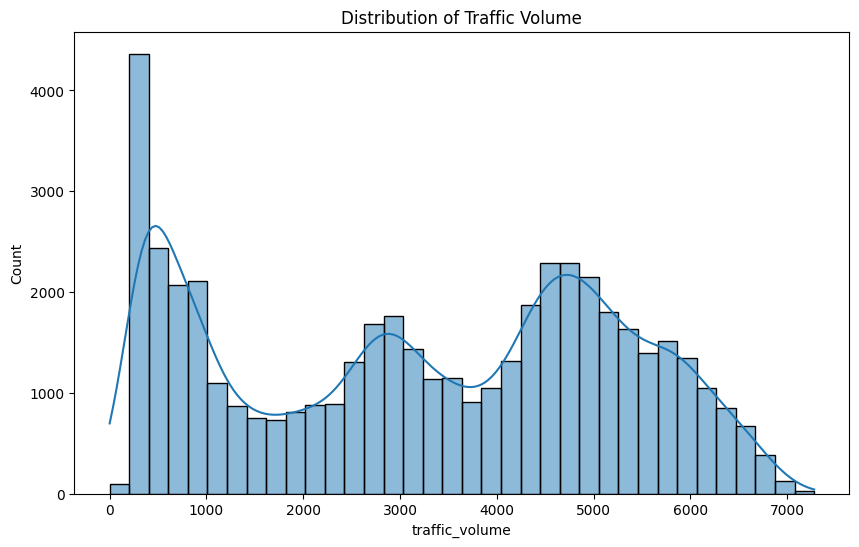

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Histogram of traffic volume
plt.figure(figsize=(10,6))
sns.histplot(df['traffic_volume'], kde=True)
plt.title('Distribution of Traffic Volume')
plt.show()

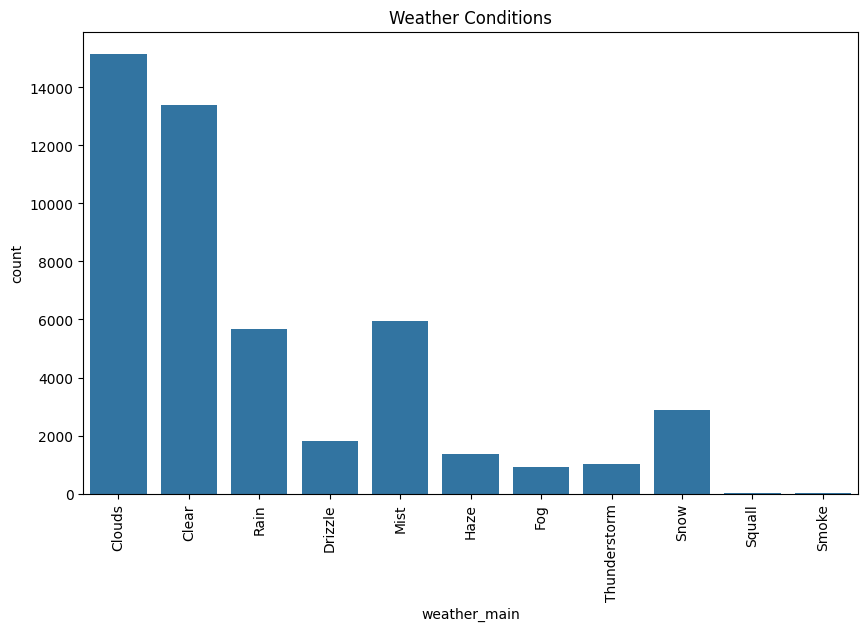

In [ ]:
# Bar plot of weather_main
plt.figure(figsize=(10,6))
sns.countplot(x='weather_main', data=df)
plt.title('Weather Conditions')
plt.xticks(rotation=90)
plt.show()

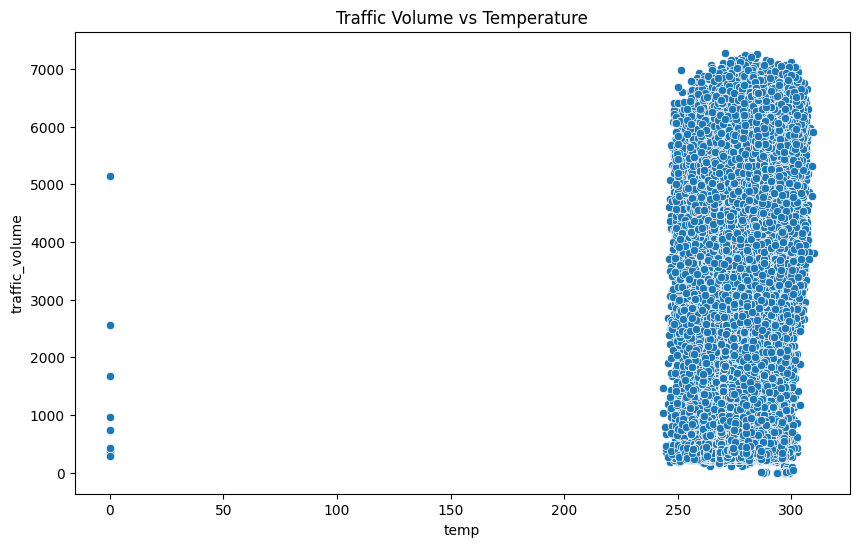

In [ ]:
# Scatter plot of traffic_volume vs temp
plt.figure(figsize=(10,6))
sns.scatterplot(x='temp', y='traffic_volume', data=df)
plt.title('Traffic Volume vs Temperature')
plt.show()

Feature Extraction

In [ ]:
# Convert to datetime with correct format
df['date_time'] = pd.to_datetime(df['date_time'], format='%d-%m-%Y %H:%M')

# Extract features
df['hour'] = df['date_time'].dt.hour
df['day_of_week'] = df['date_time'].dt.dayofweek
df['month'] = df['date_time'].dt.month

In [ ]:
# Drop unimportant features
df = df.drop(columns=['clouds_all', 'weather_description'])

In [ ]:
# Convert 'weather main' into numerical format using one-hot encoding
df = pd.get_dummies(df, columns=['weather_main'])

In [ ]:
# Scaling
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
df[['temp', 'rain_1h', 'snow_1h']] = scaler.fit_transform(df[['temp', 'rain_1h', 'snow_1h']])

In [ ]:
import numpy as np

# Instead of raw hour, consider cyclical encoding:
df['hour_sin'] = np.sin(2 * np.pi * df['hour']/24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour']/24)

# Instead of day_of_week, consider weekend flag:
df['is_weekend'] = df['day_of_week'].isin([5, 6]).astype(int)

In [ ]:
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,date_time,hour,day_of_week,month,weather_main_Clear,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
0,5545,0,0.530370,-0.007463,-0.027228,2012-10-02 09:00:00,9,1,10,False,...,False,False,False,False,False,False,False,7.071068e-01,-0.707107,0
1,4516,0,0.611341,-0.007463,-0.027228,2012-10-02 10:00:00,10,1,10,False,...,False,False,False,False,False,False,False,5.000000e-01,-0.866025,0
2,4767,0,0.627836,-0.007463,-0.027228,2012-10-02 11:00:00,11,1,10,False,...,False,False,False,False,False,False,False,2.588190e-01,-0.965926,0
3,5026,0,0.669071,-0.007463,-0.027228,2012-10-02 12:00:00,12,1,10,False,...,False,False,False,False,False,False,False,1.224647e-16,-1.000000,0
4,4918,0,0.744794,-0.007463,-0.027228,2012-10-02 13:00:00,13,1,10,False,...,False,False,False,False,False,False,False,-2.588190e-01,-0.965926,0


In [ ]:
correlation = df.corr()['traffic_volume'].abs().sort_values(ascending=False)
print(correlation)

selected_features_corr = correlation[correlation > 0.05].index.tolist()

print("\n=== Features with |correlation| > 0.05 ===")
print(selected_features_corr)

traffic_volume               1.000000
hour_cos                     0.764252
hour                         0.352401
hour_sin                     0.244211
is_weekend                   0.218647
day_of_week                  0.149544
temp                         0.130299
weather_main_Clouds          0.122285
weather_main_Clear           0.063652
weather_main_Mist            0.061734
holiday                      0.042897
weather_main_Fog             0.038868
weather_main_Snow            0.030804
weather_main_Haze            0.020778
weather_main_Thunderstorm    0.019241
weather_main_Rain            0.010676
weather_main_Squall          0.005493
rain_1h                      0.004714
date_time                    0.004449
weather_main_Drizzle         0.003082
month                        0.002533
snow_1h                      0.000733
weather_main_Smoke           0.000227
Name: traffic_volume, dtype: float64

=== Features with |correlation| > 0.05 ===
['traffic_volume', 'hour_cos', 'hour', 'hour_

Save Preprocessed Data into New CSV File

In [ ]:
df.to_csv('prediction_traffic.csv', index=False)
print("✅ Preprocessed data saved as 'prediction_traffic.csv'")

✅ Preprocessed data saved as 'prediction_traffic.csv'


Model Selection

In [ ]:
df = pd.read_csv('prediction_traffic.csv')
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,date_time,hour,day_of_week,month,weather_main_Clear,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
0,5545,0,0.530370,-0.007463,-0.027228,2012-10-02 09:00:00,9,1,10,False,...,False,False,False,False,False,False,False,7.071068e-01,-0.707107,0
1,4516,0,0.611341,-0.007463,-0.027228,2012-10-02 10:00:00,10,1,10,False,...,False,False,False,False,False,False,False,5.000000e-01,-0.866025,0
2,4767,0,0.627836,-0.007463,-0.027228,2012-10-02 11:00:00,11,1,10,False,...,False,False,False,False,False,False,False,2.588190e-01,-0.965926,0
3,5026,0,0.669071,-0.007463,-0.027228,2012-10-02 12:00:00,12,1,10,False,...,False,False,False,False,False,False,False,1.224647e-16,-1.000000,0
4,4918,0,0.744794,-0.007463,-0.027228,2012-10-02 13:00:00,13,1,10,False,...,False,False,False,False,False,False,False,-2.588190e-01,-0.965926,0


In [ ]:
df.set_index('date_time', inplace=True)
df.sort_index(inplace=True)

In [ ]:
correlation = df.corr()['traffic_volume'].abs().sort_values(ascending=False)
print(correlation)

selected_features_corr = correlation[correlation > 0.05].index.tolist()

print("\n=== Features with |correlation| > 0.05 ===")
print(selected_features_corr)

traffic_volume               1.000000
hour_cos                     0.764252
hour                         0.352401
hour_sin                     0.244211
is_weekend                   0.218647
day_of_week                  0.149544
temp                         0.130299
weather_main_Clouds          0.122285
weather_main_Clear           0.063652
weather_main_Mist            0.061734
holiday                      0.042897
weather_main_Fog             0.038868
weather_main_Snow            0.030804
weather_main_Haze            0.020778
weather_main_Thunderstorm    0.019241
weather_main_Rain            0.010676
weather_main_Squall          0.005493
rain_1h                      0.004714
weather_main_Drizzle         0.003082
month                        0.002533
snow_1h                      0.000733
weather_main_Smoke           0.000227
Name: traffic_volume, dtype: float64

=== Features with |correlation| > 0.05 ===
['traffic_volume', 'hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'te

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

#define features and target
selected_features_corr.remove('traffic_volume')

X = df[selected_features_corr]
y = df['traffic_volume']

print("Selected features for Linear Regression:", X.columns.tolist())


Selected features for Linear Regression: ['hour_cos', 'hour', 'hour_sin', 'is_weekend', 'day_of_week', 'temp', 'weather_main_Clouds', 'weather_main_Clear', 'weather_main_Mist']


In [ ]:
df.head()

,traffic_volume,holiday,temp,rain_1h,snow_1h,hour,day_of_week,month,weather_main_Clear,weather_main_Clouds,...,weather_main_Haze,weather_main_Mist,weather_main_Rain,weather_main_Smoke,weather_main_Snow,weather_main_Squall,weather_main_Thunderstorm,hour_sin,hour_cos,is_weekend
date_time,,,,,,,,,,,,,,,,,,,,,
2012-10-02 09:00:00,5545,0,0.530370,-0.007463,-0.027228,9,1,10,False,True,...,False,False,False,False,False,False,False,7.071068e-01,-0.707107,0
2012-10-02 10:00:00,4516,0,0.611341,-0.007463,-0.027228,10,1,10,False,True,...,False,False,False,False,False,False,False,5.000000e-01,-0.866025,0
2012-10-02 11:00:00,4767,0,0.627836,-0.007463,-0.027228,11,1,10,False,True,...,False,False,False,False,False,False,False,2.588190e-01,-0.965926,0
2012-10-02 12:00:00,5026,0,0.669071,-0.007463,-0.027228,12,1,10,False,True,...,False,False,False,False,False,False,False,1.224647e-16,-1.000000,0
2012-10-02 13:00:00,4918,0,0.744794,-0.007463,-0.027228,13,1,10,False,True,...,False,False,False,False,False,False,False,-2.588190e-01,-0.965926,0


In [ ]:
split_date = '2018-01-01'

train = df[df.index < split_date]
test = df[df.index >= split_date]

# 3. Define X and y for both sets
X_train = train[selected_features_corr]
y_train = train['traffic_volume']

X_test = test[selected_features_corr]
y_test = test['traffic_volume']

In [ ]:
#Linear Regression model
Linear_regression = LinearRegression()

#train model on training data
Linear_regression.fit(X_train, y_train)

LinearRegression()

Model evaluation

In [ ]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

#predict on testing data
y_pred = Linear_regression.predict(X_test)

#Calculate MSE, MAE, RMSE, R2
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred)/y_test)) * 100

print(f"Mean Absolute Error (MAE): {mae}")
print(f"Root Mean Squared Error (RMSE): {rmse}")
print(f"R2 Score:{r2}")
print(f"MAPE: {mape}")

Mean Absolute Error (MAE): 835.964643467325
Root Mean Squared Error (RMSE): 1064.0632338356413
R2 Score:0.7091327534702634
MAPE: 54.368314650240556


Residual Analysis

In [ ]:
#to check if they follow a normal distribution

#calculate residuals
residuals = y_test - y_pred

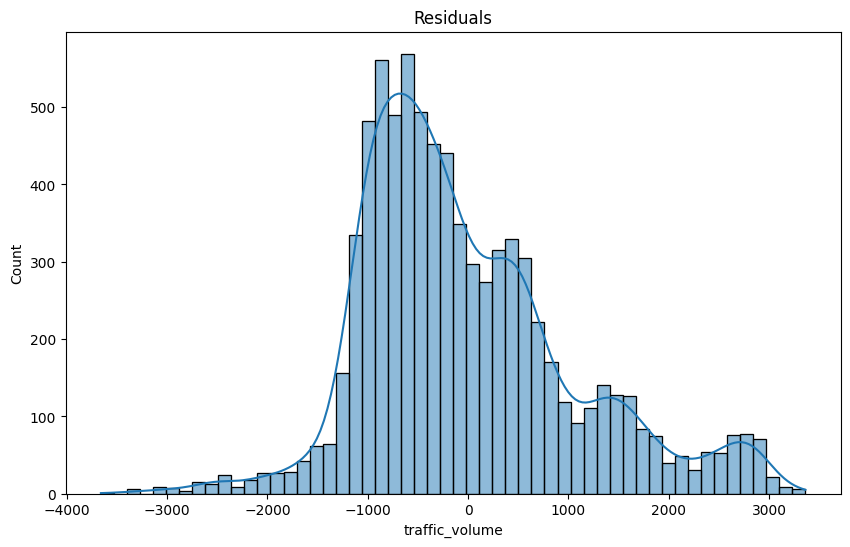

In [ ]:
#plot residuals
plt.figure(figsize=(10,6))
sns.histplot(residuals, kde=True)
plt.title('Residuals')
plt.show()

Model Deployment

In [ ]:
import joblib
#save model
joblib.dump(Linear_regression, 'traffic_volume_model.pkl')

['traffic_volume_model.pkl']

In [ ]:
import joblib
#Load the model
loaded_model = joblib.load('traffic_volume_model.pkl')

#Use the model for prediction
#use the first 100 rows of the testing data for demonstration
sample_data = X_test.iloc[:100]
predictions = loaded_model.predict(sample_data)

print(predictions)

[ 482.72052202  554.34737448  767.58253983 1111.99844822 1566.60999505
 2104.905575   2697.48371849 3302.04818453 3884.93247962 4411.73440817
 4858.61983617 5191.66931826 5388.67528853 5443.26869883 5357.97380043
 5136.53660845 4801.66223168 4376.22380504 3895.11358071 3403.80319203
 2932.51912411 2520.36050707 2201.48150002 1995.90920683  550.14580083
  611.2939452   836.4632068  1181.80527129 1637.40912823 2176.16778623
 2767.88592763 3372.05346962 3957.517771   4486.37047376 4938.01899029
 5288.28868574 5492.50544279 5556.88964616 5468.81627946 5236.4435048
 4833.14129819 4888.44425965 4412.46596007 4467.76892153 3940.41883472
 3940.41883472 3456.84846489 3512.15142635 2992.84133776 2586.9673514
 2265.44218407 2060.33296893  609.07878033  676.40562232  676.40562232
  885.80385526 1298.80007299 1742.21142111 2275.28083449 2864.55127763
 3476.74362598 4049.02310843 4574.63426484 5017.3519904  5349.23087185
 5544.38452991 5594.61177573 5502.37070658 5267.68254167 4930.62508266
 4502.67

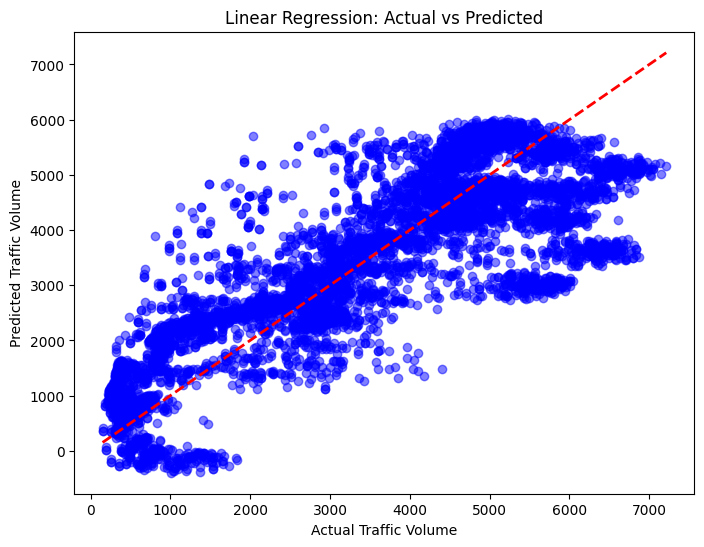

In [ ]:
import matplotlib.pyplot as plt
y_pred = Linear_regression.predict(X_test)

# Plot 1: Scatter plot
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Traffic Volume")
plt.ylabel("Predicted Traffic Volume")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

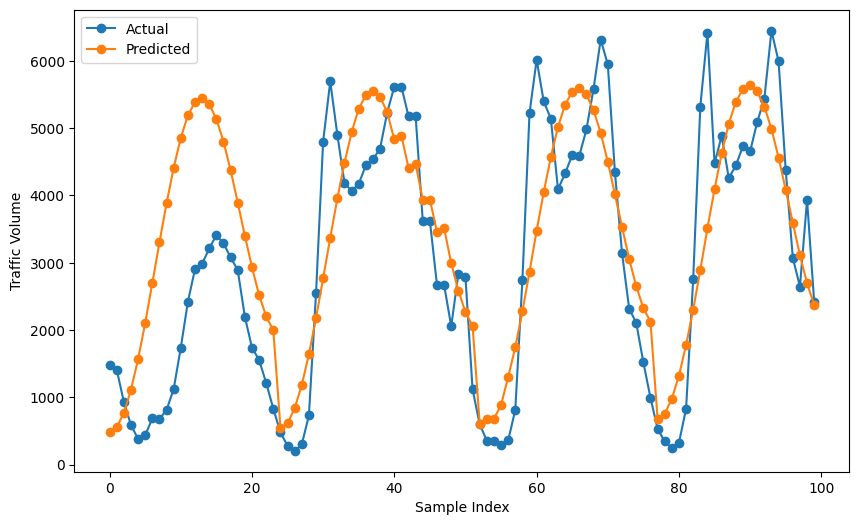

In [ ]:
import matplotlib.pyplot as plt

# Plot 2: 100 samples
plt.figure(figsize=(10,6))
plt.plot(range(100), y_test.iloc[:100], label='Actual', marker='o')
plt.plot(range(100), predictions, label='Predicted', marker='o')
plt.xlabel('Sample Index')
plt.ylabel('Traffic Volume')
plt.legend()
plt.show()

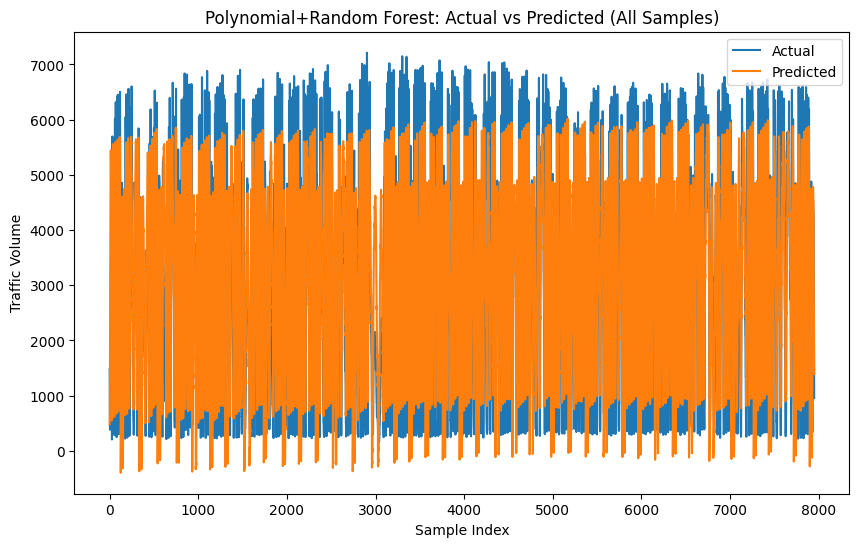

In [ ]:
import matplotlib.pyplot as plt

# Plot 3: all samples
plt.figure(figsize=(10,6))
plt.plot(y_test.values, label='Actual')
plt.plot(y_pred, label='Predicted')
plt.xlabel('Sample Index')
plt.ylabel('Traffic Volume')
plt.title('Polynomial+Random Forest: Actual vs Predicted (All Samples)')
plt.legend()
plt.show()